# Análisis de los errores de NER

## Falta asear

In [2]:
import json

In [1]:
PATH_PREDICTIONS = "predictions/13-06/michi_crf.json"
PATH_GOLDEN = "dev.json"

In [3]:


def replace_label(data):
    if isinstance(data, dict):
        for key, value in data.items():
            # Cambiar valor si es label
            if key in ["entity_label", "label", "tag"] and value == "ddf":
                data[key] = "DDF"
            else:
                replace_label(value)

    elif isinstance(data, list):
        for item in data:
            replace_label(item)

    return data


# Cargar JSON
with open(PATH_PREDICTIONS, "r", encoding="utf-8") as f:
    predictions = json.load(f)

# Reemplazar
# data = replace_label(data)

# # Guardar
# with open(PATH_PREDICTIONS, "w", encoding="utf-8") as f:
#     json.dump(data, f, ensure_ascii=False, indent=2)

In [3]:
import json

INPUT_PATH = "../Scripts/predicted_ents_dev_merged.json"
OUTPUT_PATH = "./filtered2.json"

THRESHOLD = 0.75

with open(INPUT_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

filtered_data = {}

for pmid, content in data.items():
    entities = content.get("entities", [])
    
    # Filtrar entidades por score
    filtered_entities = [
        ent for ent in entities if ent.get("score", 0) > THRESHOLD
    ]
    
    # Guardar resultado
    filtered_data[pmid] = {
        **content,
        "entities": filtered_entities
    }

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(filtered_data, f, ensure_ascii=False, indent=2)

print("Filtrado completado")

Filtrado completado


In [6]:
# with open(PATH_PREDICTIONS, "r", encoding = "utf-8") as file1:
#     predictions = json.load(file1)
# predictions = replace_label(predictions)
# with open("predictions/FORMATED2.json", "w", encoding="utf-8") as f:
#     json.dump(predictions, f, ensure_ascii=False, indent=2)
with open(PATH_GOLDEN, "r") as file2:
    golden  = json.load(file2)
valid_pmids = predictions.keys()
golden = {k:v for k, v in golden.items() if k in valid_pmids}

In [8]:
predictions = filtered_data

In [4]:
from collections import defaultdict
import pandas as pd


def normalize_entity(ent):
    """
    Adapta aquí los nombres de campos si tu JSON usa otros.
    GLiNER suele usar start_idx, end_idx, entity_label/text_span.
    """
    return {
        "start": ent.get("start", ent.get("start_idx")),
        "end": ent.get("end", ent.get("end_idx")),
        "label": ent.get("label", ent.get("entity_label", ent.get("tag")))
    }


def evaluate_ner(gold_data, pred_data):
    """
    gold_data y pred_data deben tener esta forma:
    
    {
        "pmid1": {"entities": [...]},
        "pmid2": {"entities": [...]}
    }
    
    En pred_data puede llamarse "entities" o "pred_entities".
    """

    global_tp = 0
    global_fp = 0
    global_fn = 0

    per_class = defaultdict(lambda: {"TP": 0, "FP": 0, "FN": 0})

    # Matriz gold_label -> pred_label
    confusion = defaultdict(lambda: defaultdict(int))

    all_pmids = set(gold_data.keys()) | set(pred_data.keys())

    for pmid in all_pmids:
        gold_entities = [
            normalize_entity(e)
            for e in gold_data.get(pmid, {}).get("entities", [])
        ]

        pred_entities = [
            normalize_entity(e)
            for e in pred_data.get(pmid, {}).get(
                "entities",
                pred_data.get(pmid, {}).get("pred_entities", [])
            )
        ]

        gold_exact = {
            (e["start"], e["end"], e["label"])
            for e in gold_entities
        }

        pred_exact = {
            (e["start"], e["end"], e["label"])
            for e in pred_entities
        }

        tp_set = gold_exact & pred_exact
        fp_set = pred_exact - gold_exact
        fn_set = gold_exact - pred_exact

        global_tp += len(tp_set)
        global_fp += len(fp_set)
        global_fn += len(fn_set)

        for _, _, label in tp_set:
            per_class[label]["TP"] += 1

        for _, _, label in fp_set:
            per_class[label]["FP"] += 1

        for _, _, label in fn_set:
            per_class[label]["FN"] += 1

        # Confusión por clase SOLO cuando el span coincide
        gold_by_span = {
            (e["start"], e["end"]): e["label"]
            for e in gold_entities
        }

        pred_by_span = {
            (e["start"], e["end"]): e["label"]
            for e in pred_entities
        }

        for span in set(gold_by_span.keys()) & set(pred_by_span.keys()):
            gold_label = gold_by_span[span]
            pred_label = pred_by_span[span]
            confusion[gold_label][pred_label] += 1

    precision = global_tp / (global_tp + global_fp) if global_tp + global_fp > 0 else 0
    recall = global_tp / (global_tp + global_fn) if global_tp + global_fn > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0

    per_class_rows = []

    for label, counts in per_class.items():
        tp = counts["TP"]
        fp = counts["FP"]
        fn = counts["FN"]

        p = tp / (tp + fp) if tp + fp > 0 else 0
        r = tp / (tp + fn) if tp + fn > 0 else 0
        f = 2 * p * r / (p + r) if p + r > 0 else 0

        per_class_rows.append({
            "label": label,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "precision": p,
            "recall": r,
            "f1": f
        })

    per_class_df = pd.DataFrame(per_class_rows).sort_values("label")

    labels = sorted(set(confusion.keys()) | {
        pred_label
        for row in confusion.values()
        for pred_label in row.keys()
    })

    confusion_df = pd.DataFrame(
        0,
        index=labels,
        columns=labels
    )

    for gold_label, preds in confusion.items():
        for pred_label, count in preds.items():
            confusion_df.loc[gold_label, pred_label] = count

    global_metrics = {
        "TP": global_tp,
        "FP": global_fp,
        "FN": global_fn,
        "TN": None,  # En NER span-level no se calcula de forma útil
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

    return global_metrics, per_class_df, confusion_df

In [8]:

global_metrics, per_class_df, confusion_df = evaluate_ner(golden, predictions)

print(per_class_df)

                    label   TP  FP  FN  precision    recall        f1
0                     DDF  362  46  22   0.887255  0.942708  0.914141
1     anatomical location   65  37  12   0.637255  0.844156  0.726257
11                 animal   51  20  12   0.718310  0.809524  0.761194
10               bacteria   67  18  12   0.788235  0.848101  0.817073
5    biomedical technique   35  31  33   0.530303  0.514706  0.522388
9                chemical  139  60  43   0.698492  0.763736  0.729659
2      dietary supplement   28   6   3   0.823529  0.903226  0.861538
3                    drug   30   8   1   0.789474  0.967742  0.869565
7                    food   15   4   4   0.789474  0.789474  0.789474
6                    gene    7  17  20   0.291667  0.259259  0.274510
8                   human   82   6   1   0.931818  0.987952  0.959064
4              microbiome  105  15  10   0.875000  0.913043  0.893617
12  statistical technique   12   3   5   0.800000  0.705882  0.750000


In [6]:
import matplotlib.pyplot as plt

def plot_per_class_metrics(per_class_df):
    plt.figure()
    
    labels = per_class_df["label"]

    plt.plot(labels, per_class_df["precision"], marker='o', label="Precision")
    plt.plot(labels, per_class_df["recall"], marker='o', label="Recall")
    plt.plot(labels, per_class_df["f1"], marker='o', label="F1")

    plt.xlabel("Clase de entidad")
    plt.ylabel("Score")
    plt.title("Métricas por clase (NER)")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()

    plt.show()



import numpy as np

def plot_confusion_matrix(confusion_df):
    plt.figure()

    matrix = confusion_df.values

    plt.imshow(matrix)
    plt.colorbar()

    labels = confusion_df.index

    plt.xticks(range(len(labels)), labels, rotation=45)
    plt.yticks(range(len(labels)), labels)

    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.title("Matriz de confusión (NER)")

    # Añadir números dentro de la matriz
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            plt.text(j, i, int(matrix[i, j]),
                     ha="center", va="center")

    plt.tight_layout()
    plt.show()

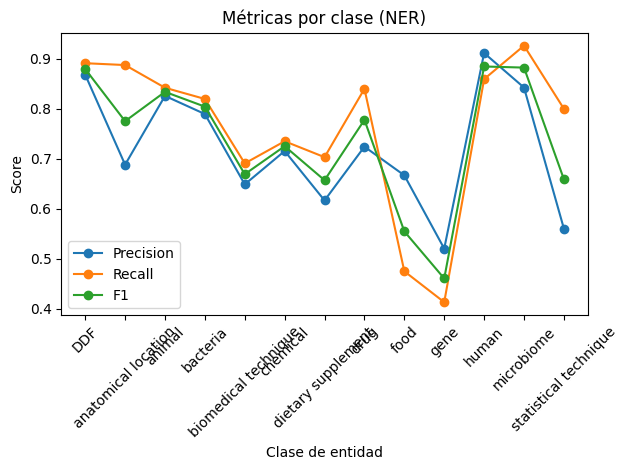

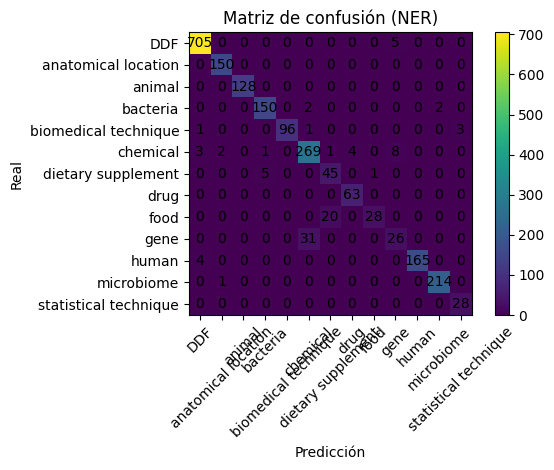

In [9]:
plot_per_class_metrics(per_class_df)
plot_confusion_matrix(confusion_df)

In [20]:
from collections import defaultdict
import pandas as pd
def remove_duplicated_entities(predictions: dict) -> None:
    removed_count = 0
    for pmid in list(predictions.keys()):
        seen = set()
        deduped = []
        for ent in predictions[pmid]["entities"]:
            key = (ent["start_idx"], ent["end_idx"], ent["location"])
            if key not in seen:
                seen.add(key)
                deduped.append(ent)
            else:
                removed_count += 1
        predictions[pmid]["entities"] = deduped
    
    if removed_count > 0:
        print(f"=== Removed {removed_count} duplicated entities from predictions ===")
    else:
        print("=== No duplicated entities found in predictions ===")
        pass

def remove_overlapping_entities(predictions: dict) -> None:
    removed_count = 0

    # Iterate over PMIDs
    for pmid in list(predictions.keys()):
        original_len = len(predictions[pmid]['entities'])
        
        # Group entities by location
        groups = {'title': [], 'abstract': []}
        for ent in predictions[pmid]['entities']:
            loc = ent["location"]
            groups[loc].append(ent)

        # For each location, build overlap clusters and select the longest
        keepers = set()
        for loc in groups:
            group = groups[loc]
            # sort by start_idx so we have overlapping entities contiguous
            group = sorted(group, key=lambda e: e["start_idx"])

            clusters = []
            cluster = []
            current_end = None

            for ent in group:
                if not cluster:
                    # start the first cluster
                    cluster = [ent]
                    current_end = ent["end_idx"]
                else:
                    # check overlap: ent.start_idx < current_end
                    if ent["start_idx"] < current_end:
                        cluster.append(ent)
                        # extend cluster span if needed
                        if ent["end_idx"] > current_end:
                            current_end = ent["end_idx"]
                    else:
                        clusters.append(cluster)
                        cluster = [ent]
                        current_end = ent["end_idx"]
            if cluster:
                clusters.append(cluster)

            # pick the longest entity in each cluster
            for clust in clusters:
                # initialize with first entity
                longest = clust[0]
                max_len = longest["end_idx"] - longest["start_idx"]
                # compare with the rest
                for ent in clust[1:]:
                    length = ent["end_idx"] - ent["start_idx"]
                    if length > max_len:
                        longest = ent
                        max_len = length
                # track by (start, end, loc)
                keepers.add((longest["start_idx"],
                             longest["end_idx"],
                             longest["location"]))

        # Rebuild the entity list in original order, keeping only the keepers
        deduped = []
        for ent in predictions[pmid]['entities']:
            key = (ent["start_idx"], ent["end_idx"], ent["location"])
            if key in keepers:
                deduped.append(ent)
                keepers.remove(key)  # avoid duplicates

        predictions[pmid]["entities"] = deduped

        # count how many overlapping entities have been removed for this document
        removed_count += (original_len - len(deduped))

    if removed_count > 0:
        print(f"=== Removed {removed_count} overlapping entities ===")
    else:
        print("=== No overlapping entity found ===")
        pass

def evaluate_ner_like_competition(ground_truth, predictions, legal_entity_labels=None):
    ground_truth_NER = {}
    count_annotated_entities_per_label = {}
    remove_duplicated_entities(predictions)
    remove_overlapping_entities(predictions)

    # ---------- GOLD ----------
    for pmid, article in ground_truth.items():
        if pmid not in ground_truth_NER:
            ground_truth_NER[pmid] = []

        for entity in article["entities"]:
            start_idx = int(entity["start_idx"])
            end_idx = int(entity["end_idx"])
            location = str(entity["location"])
            text_span = str(entity["text_span"])
            label = str(entity["label"])

            entry = (start_idx, end_idx, location, text_span, label)
            ground_truth_NER[pmid].append(entry)

            if label not in count_annotated_entities_per_label:
                count_annotated_entities_per_label[label] = 0
            count_annotated_entities_per_label[label] += 1

    labels = list(count_annotated_entities_per_label.keys())

    count_predicted_entities_per_label = {label: 0 for label in labels}
    count_true_positives_per_label = {label: 0 for label in labels}

    # Para matriz de confusión por clase
    confusion = defaultdict(lambda: defaultdict(int))

    # Para contar FP/FN por clase
    predicted_entries_per_label = defaultdict(list)
    gold_entries_per_label = defaultdict(list)

    for pmid, entries in ground_truth_NER.items():
        for entry in entries:
            gold_entries_per_label[entry[-1]].append((pmid, entry))

    # ---------- PREDICTIONS ----------
    for pmid in predictions.keys():
        try:
            entities = predictions[pmid]["entities"]
        except KeyError:
            raise KeyError(f'{pmid} - Not able to find field "entities" within article')

        for entity in entities:
            try:
                start_idx = int(entity["start_idx"])
                end_idx = int(entity["end_idx"])
                location = str(entity["location"])
                text_span = str(entity["text_span"])
                label = str(entity["label"])
            except KeyError:
                raise KeyError(
                    f"{pmid} - Not able to find one or more expected fields for entity: {entity}"
                )

            if legal_entity_labels is not None and label not in legal_entity_labels:
                raise NameError(f"{pmid} - Illegal label {label} for entity: {entity}")

            entry = (start_idx, end_idx, location, text_span, label)

            if label in count_predicted_entities_per_label:
                count_predicted_entities_per_label[label] += 1
                predicted_entries_per_label[label].append((pmid, entry))

            if pmid in ground_truth_NER and entry in ground_truth_NER[pmid]:
                count_true_positives_per_label[label] += 1

    # ---------- GLOBAL COUNTS ----------
    count_annotated_entities = sum(count_annotated_entities_per_label[label] for label in labels)
    count_predicted_entities = sum(count_predicted_entities_per_label[label] for label in labels)
    count_true_positives = sum(count_true_positives_per_label[label] for label in labels)

    micro_precision = count_true_positives / (count_predicted_entities + 1e-10)
    micro_recall = count_true_positives / (count_annotated_entities + 1e-10)
    micro_f1 = 2 * (
        (micro_precision * micro_recall) /
        (micro_precision + micro_recall + 1e-10)
    )

    # ---------- MACRO ----------
    precision = 0
    recall = 0
    f1 = 0

    rows = []

    for label in labels:
        tp = count_true_positives_per_label[label]
        pred = count_predicted_entities_per_label[label]
        gold = count_annotated_entities_per_label[label]

        fp = pred - tp
        fn = gold - tp

        current_precision = tp / (pred + 1e-10)
        current_recall = tp / (gold + 1e-10)
        current_f1 = 2 * (
            (current_precision * current_recall) /
            (current_precision + current_recall + 1e-10)
        )

        precision += current_precision
        recall += current_recall
        f1 += current_f1

        rows.append({
            "label": label,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": None,
            "gold_count": gold,
            "pred_count": pred,
            "precision": current_precision,
            "recall": current_recall,
            "f1": current_f1,
        })

    n = len(labels)
    precision = precision / n
    recall = recall / n
    f1 = f1 / n

    per_class_df = pd.DataFrame(rows).sort_values("label")

    global_metrics = {
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
        "precision_micro": micro_precision,
        "recall_micro": micro_recall,
        "f1_micro": micro_f1,
        "TP": count_true_positives,
        "FP": count_predicted_entities - count_true_positives,
        "FN": count_annotated_entities - count_true_positives,
        "TN": None,
        "gold_total": count_annotated_entities,
        "pred_total": count_predicted_entities,
    }

    return global_metrics, per_class_df

In [29]:
LEGAL_ENTITY_LABELS = [
    "anatomical location",
    "animal",
    "bacteria",
    "biomedical technique",
    "chemical",
    "DDF",
    "dietary supplement",
    "drug",
    "food",
    "gene",
    "human",
    "microbiome",
    "statistical technique"
]

global_metrics, per_class_df, confusion_df = evaluate_ner_like_competition_with_confusion(
    ground_truth=golden,
    predictions=predictions,
    legal_entity_labels=LEGAL_ENTITY_LABELS
)

print(global_metrics)
print(per_class_df)

=== Removed 31 duplicated entities from predictions ===
=== Removed 6 overlapping entities ===
{'precision_macro': 0.7213192411184538, 'recall_macro': 0.7872698091373647, 'f1_macro': 0.7474033450562985, 'precision_micro': 0.8012924071081743, 'recall_micro': 0.8435374149659146, 'f1_micro': 0.8218724108861704, 'TP': 992, 'FP': 246, 'FN': 184, 'gold_total': 1176, 'pred_total': 1238}
                    label   TP  FP  FN  gold_count  pred_count  TP/gold_count  \
0                     DDF  358  40  26         384         398       0.932292   
8     anatomical location   67  28  10          77          95       0.870130   
7                  animal   55  10   8          63          65       0.873016   
5                bacteria   62  19  17          79          81       0.784810   
3    biomedical technique   43  14  25          68          57       0.632353   
4                chemical  137  56  45         182         193       0.752747   
10     dietary supplement   24   6   7          31

In [30]:
ratio_df = per_class_df[["label", "TP", "gold_count"]].copy()

ratio_df["TP/gold_count"] = ratio_df["TP"] / (ratio_df["gold_count"] + 1e-10)

ratio_df = ratio_df.sort_values("TP/gold_count", ascending=False)

print(ratio_df)

                    label   TP  gold_count  TP/gold_count
1                   human   80          83       0.963855
12                   drug   29          31       0.935484
0                     DDF  358         384       0.932292
2              microbiome  103         115       0.895652
11  statistical technique   15          17       0.882353
7                  animal   55          63       0.873016
8     anatomical location   67          77       0.870130
9                    food   15          19       0.789474
5                bacteria   62          79       0.784810
10     dietary supplement   24          31       0.774194
4                chemical  137         182       0.752747
3    biomedical technique   43          68       0.632353
6                    gene    4          27       0.148148


In [18]:
from collections import defaultdict
import pandas as pd


def evaluate_ner_like_competition_with_confusion(
    ground_truth,
    predictions,
    legal_entity_labels=None
):
    ground_truth_NER = {}
    count_annotated_entities_per_label = {}
    remove_duplicated_entities(predictions)
    remove_overlapping_entities(predictions)

    # ---------- GOLD ----------
    for pmid, article in ground_truth.items():
        ground_truth_NER[pmid] = []

        for entity in article["entities"]:
            start_idx = int(entity["start_idx"])
            end_idx = int(entity["end_idx"])
            location = str(entity["location"])
            text_span = str(entity["text_span"])
            label = str(entity["label"])

            entry = (start_idx, end_idx, location, text_span, label)
            ground_truth_NER[pmid].append(entry)

            count_annotated_entities_per_label[label] = (
                count_annotated_entities_per_label.get(label, 0) + 1
            )

    labels = list(count_annotated_entities_per_label.keys())

    count_predicted_entities_per_label = {label: 0 for label in labels}
    count_true_positives_per_label = {label: 0 for label in labels}

    # Para matriz de confusión:
    # clave sin label -> label gold
    gold_by_span_text = defaultdict(dict)

    for pmid, entries in ground_truth_NER.items():
        for start_idx, end_idx, location, text_span, label in entries:
            key = (start_idx, end_idx, location, text_span)
            gold_by_span_text[pmid][key] = label

    confusion_counts = defaultdict(lambda: defaultdict(int))

    # ---------- PREDICTIONS ----------
    for pmid in predictions.keys():
        try:
            entities = predictions[pmid]["entities"]
        except KeyError:
            raise KeyError(f'{pmid} - Not able to find field "entities" within article')

        for entity in entities:
            try:
                start_idx = int(entity["start_idx"])
                end_idx = int(entity["end_idx"])
                location = str(entity["location"])
                text_span = str(entity["text_span"])
                label = str(entity["label"])
            except KeyError:
                raise KeyError(
                    f"{pmid} - Missing expected fields for entity: {entity}"
                )

            if legal_entity_labels is not None and label not in legal_entity_labels:
                raise NameError(f"{pmid} - Illegal label {label} for entity: {entity}")

            entry = (start_idx, end_idx, location, text_span, label)

            if label in count_predicted_entities_per_label:
                count_predicted_entities_per_label[label] += 1

            if pmid in ground_truth_NER and entry in ground_truth_NER[pmid]:
                count_true_positives_per_label[label] += 1

            # Confusion matrix por clase si coincide todo menos label
            key_without_label = (start_idx, end_idx, location, text_span)

            if (
                pmid in gold_by_span_text
                and key_without_label in gold_by_span_text[pmid]
            ):
                gold_label = gold_by_span_text[pmid][key_without_label]
                pred_label = label
                confusion_counts[gold_label][pred_label] += 1

    # ---------- MÉTRICAS ----------
    rows = []

    for label in labels:
        tp = count_true_positives_per_label[label]
        pred = count_predicted_entities_per_label[label]
        gold = count_annotated_entities_per_label[label]

        fp = pred - tp
        fn = gold - tp

        precision = tp / (pred + 1e-10)
        recall = tp / (gold + 1e-10)
        f1 = 2 * precision * recall / (precision + recall + 1e-10)

        rows.append({
            "label": label,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "gold_count": gold,
            "pred_count": pred,
            "TP/gold_count": tp / (gold + 1e-10),
            "precision": precision,
            "recall": recall,
            "f1": f1
        })

    per_class_df = pd.DataFrame(rows).sort_values("label")

    # ---------- GLOBAL ----------
    total_tp = sum(count_true_positives_per_label.values())
    total_pred = sum(count_predicted_entities_per_label.values())
    total_gold = sum(count_annotated_entities_per_label.values())

    micro_precision = total_tp / (total_pred + 1e-10)
    micro_recall = total_tp / (total_gold + 1e-10)
    micro_f1 = 2 * micro_precision * micro_recall / (
        micro_precision + micro_recall + 1e-10
    )

    macro_precision = per_class_df["precision"].mean()
    macro_recall = per_class_df["recall"].mean()
    macro_f1 = per_class_df["f1"].mean()

    global_metrics = {
        "precision_macro": macro_precision,
        "recall_macro": macro_recall,
        "f1_macro": macro_f1,
        "precision_micro": micro_precision,
        "recall_micro": micro_recall,
        "f1_micro": micro_f1,
        "TP": total_tp,
        "FP": total_pred - total_tp,
        "FN": total_gold - total_tp,
        "gold_total": total_gold,
        "pred_total": total_pred,
    }

    # ---------- CONFUSION DF ----------
    confusion_labels = sorted(
        set(labels)
        | {
            pred_label
            for gold_label in confusion_counts
            for pred_label in confusion_counts[gold_label]
        }
    )

    confusion_df = pd.DataFrame(
        0,
        index=confusion_labels,
        columns=confusion_labels
    )

    for gold_label, pred_dict in confusion_counts.items():
        for pred_label, count in pred_dict.items():
            confusion_df.loc[gold_label, pred_label] = count

    return global_metrics, per_class_df, confusion_df

In [25]:
import matplotlib.pyplot as plt
import numpy as np

def plot_confusion_heatmap(confusion_df, normalize=False, save_path="mapa_de_calor_errores.png"):
    matrix = confusion_df.values.astype(float)

    # Normalización opcional (muy recomendable)
    if normalize:
        row_sums = matrix.sum(axis=1, keepdims=True)
        matrix = np.divide(matrix, row_sums, where=row_sums != 0)

    plt.figure(figsize=(10, 8))

    plt.imshow(matrix, cmap = "Blues")
    plt.colorbar()

    labels = confusion_df.index
    labels = [label if label == "DDF" else label.title() for label in labels]

    plt.xticks(range(len(labels)), labels, rotation=45, ha="right")
    plt.yticks(range(len(labels)), labels)

    plt.xlabel("Predicción")
    plt.ylabel("Real")

    # Añadir valores dentro de cada celda
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix[i, j]

            if normalize:
                if value < 0.01:
                    continue
                text = f"{value:.2f}"
            else:
                text = str(int(value))

            plt.text(j, i, text, ha="center", va="center")

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

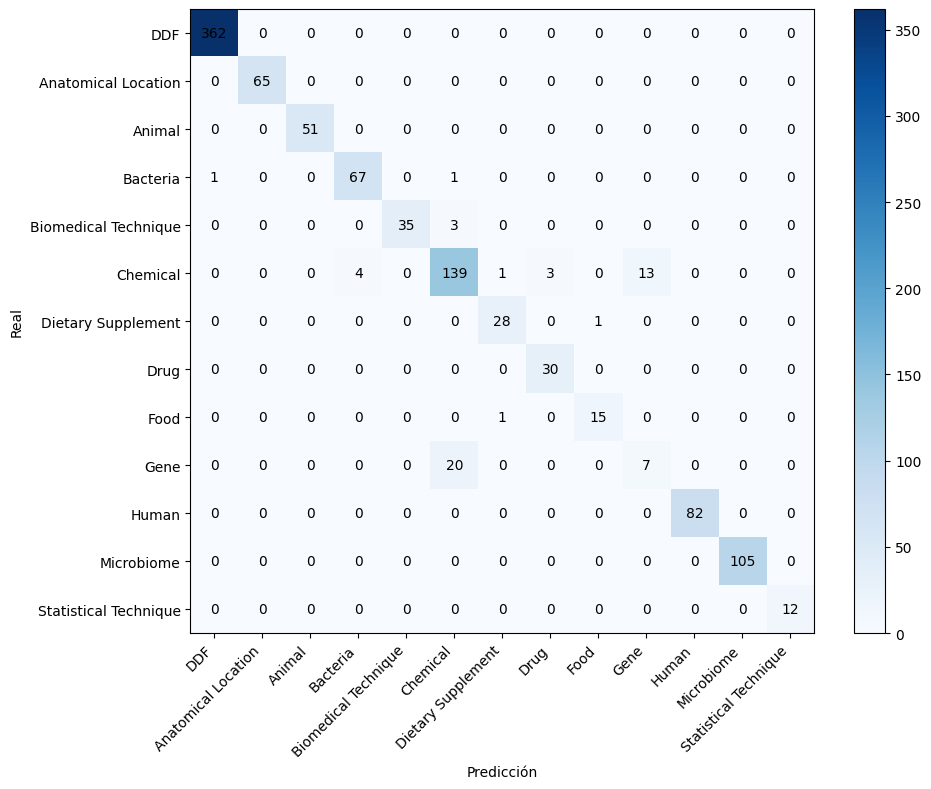

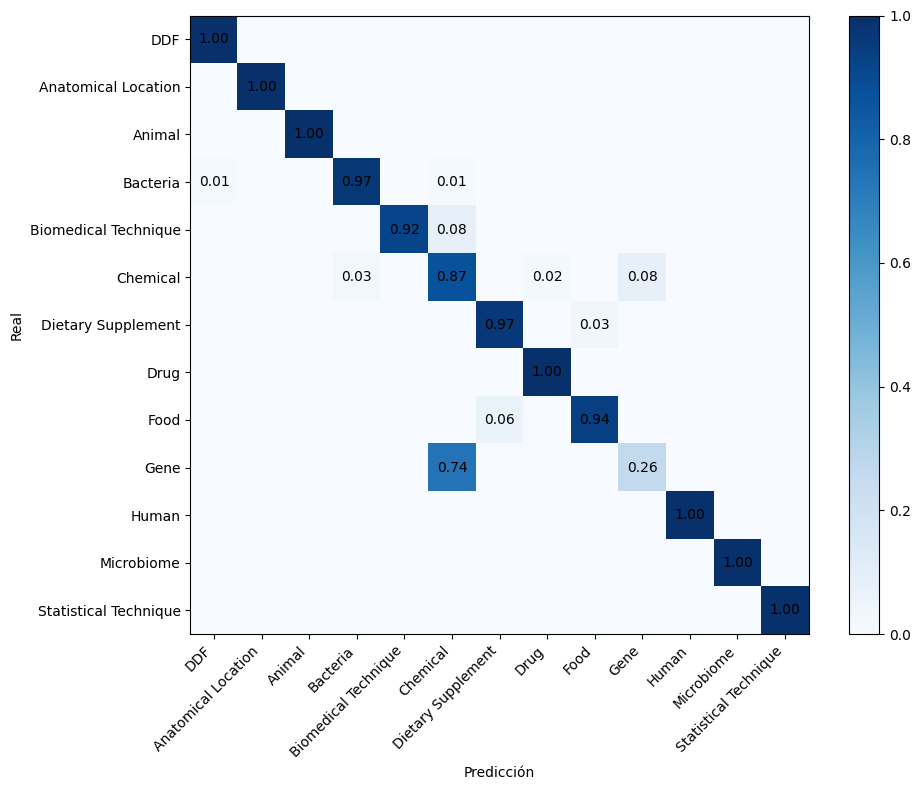

In [27]:
# Heatmap con conteos
plot_confusion_heatmap(confusion_df)

# Heatmap normalizado (MUY recomendado)
plot_confusion_heatmap(confusion_df, normalize=True)

In [12]:
from collections import defaultdict

def analyze_fp(ground_truth, predictions):
    stats = {
        "total_fp": 0,
        "exact_match": 0,        # debería ser 0 (son TP realmente)
        "span_text_match": 0,    # todo igual menos label
        "span_match": 0,         # mismo start/end
        "overlap": 0,            # overlap parcial
        "no_match": 0
    }

    def overlap(a_start, a_end, b_start, b_end):
        return max(a_start, b_start) < min(a_end, b_end)

    for pmid in predictions:
        pred_entities = predictions[pmid].get("entities", [])
        gold_entities = ground_truth.get(pmid, {}).get("entities", [])

        # Normalizar gold
        gold_entries = []
        for g in gold_entities:
            gold_entries.append({
                "start": int(g["start_idx"]),
                "end": int(g["end_idx"]),
                "location": str(g["location"]),
                "text": str(g["text_span"]),
                "label": str(g["label"])
            })

        for p in pred_entities:
            pred = {
                "start": int(p["start_idx"]),
                "end": int(p["end_idx"]),
                "location": str(p["location"]),
                "text": str(p["text_span"]),
                "label": str(p["label"])
            }

            # Check exact match (TP)
            is_tp = False
            for g in gold_entries:
                if pred == g:
                    is_tp = True
                    break

            if is_tp:
                continue  # no es FP

            stats["total_fp"] += 1

            matched = False

            for g in gold_entries:
                # match todo menos label
                if (
                    pred["start"] == g["start"] and
                    pred["end"] == g["end"] and
                    pred["location"] == g["location"] and
                    pred["text"] == g["text"]
                ):
                    stats["span_text_match"] += 1
                    matched = True
                    break

            if matched:
                continue

            for g in gold_entries:
                # match solo span
                if pred["start"] == g["start"] and pred["end"] == g["end"]:
                    stats["span_match"] += 1
                    matched = True
                    break

            if matched:
                continue

            for g in gold_entries:
                # overlap
                if overlap(pred["start"], pred["end"], g["start"], g["end"]):
                    stats["overlap"] += 1
                    matched = True
                    break

            if not matched:
                stats["no_match"] += 1

    return stats

In [13]:
fp_stats = analyze_fp(golden, predictions)

print(fp_stats)

total = fp_stats["total_fp"]

for k, v in fp_stats.items():
    if k != "total_fp":
        print(k, v / total)

{'total_fp': 634, 'exact_match': 0, 'span_text_match': 112, 'span_match': 2, 'overlap': 193, 'no_match': 327}
exact_match 0.0
span_text_match 0.17665615141955837
span_match 0.0031545741324921135
overlap 0.30441640378548895
no_match 0.5157728706624606


In [14]:
import json

def analyze_errors_with_examples(ground_truth, predictions):
    results = {
        "FP": {
            "span_text_match": [],
            "span_match": [],
            "overlap": [],
            "no_match": []
        },
        "FN": {
            "label_error": [],
            "span_match": [],
            "overlap": [],
            "no_match": []
        }
    }

    def overlap(a_start, a_end, b_start, b_end):
        return max(a_start, b_start) < min(a_end, b_end)

    for pmid in set(ground_truth.keys()) | set(predictions.keys()):
        gold_entities = ground_truth.get(pmid, {}).get("entities", [])
        pred_entities = predictions.get(pmid, {}).get("entities", [])

        # Normalizar
        gold_list = [{
            "start": int(g["start_idx"]),
            "end": int(g["end_idx"]),
            "location": str(g["location"]),
            "text": str(g["text_span"]),
            "label": str(g["label"])
        } for g in gold_entities]

        pred_list = [{
            "start": int(p["start_idx"]),
            "end": int(p["end_idx"]),
            "location": str(p["location"]),
            "text": str(p["text_span"]),
            "label": str(p["label"])
        } for p in pred_entities]

        # ---------- FP ----------
        for p in pred_list:
            if p in gold_list:
                continue  # TP

            matched = False

            for g in gold_list:
                if (
                    p["start"] == g["start"] and
                    p["end"] == g["end"] and
                    p["location"] == g["location"] and
                    p["text"] == g["text"]
                ):
                    results["FP"]["span_text_match"].append({
                        "pmid": pmid,
                        "pred": p,
                        "gold": g
                    })
                    matched = True
                    break

            if matched:
                continue

            for g in gold_list:
                if p["start"] == g["start"] and p["end"] == g["end"]:
                    results["FP"]["span_match"].append({
                        "pmid": pmid,
                        "pred": p,
                        "gold": g
                    })
                    matched = True
                    break

            if matched:
                continue

            for g in gold_list:
                if overlap(p["start"], p["end"], g["start"], g["end"]):
                    results["FP"]["overlap"].append({
                        "pmid": pmid,
                        "pred": p,
                        "gold": g
                    })
                    matched = True
                    break

            if not matched:
                results["FP"]["no_match"].append({
                    "pmid": pmid,
                    "pred": p,
                    "gold": None
                })

        # ---------- FN ----------
        for g in gold_list:
            if g in pred_list:
                continue  # TP

            matched = False

            for p in pred_list:
                if (
                    g["start"] == p["start"] and
                    g["end"] == p["end"] and
                    g["location"] == p["location"] and
                    g["text"] == p["text"]
                ):
                    results["FN"]["label_error"].append({
                        "pmid": pmid,
                        "gold": g,
                        "pred": p
                    })
                    matched = True
                    break

            if matched:
                continue

            for p in pred_list:
                if g["start"] == p["start"] and g["end"] == p["end"]:
                    results["FN"]["span_match"].append({
                        "pmid": pmid,
                        "gold": g,
                        "pred": p
                    })
                    matched = True
                    break

            if matched:
                continue

            for p in pred_list:
                if overlap(g["start"], g["end"], p["start"], p["end"]):
                    results["FN"]["overlap"].append({
                        "pmid": pmid,
                        "gold": g,
                        "pred": p
                    })
                    matched = True
                    break

            if not matched:
                results["FN"]["no_match"].append({
                    "pmid": pmid,
                    "gold": g,
                    "pred": None
                })

    return results

In [18]:
results = analyze_errors_with_examples(golden, predictions)

with open("error_analysis.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

In [16]:
def analyze_fp(ground_truth, predictions):
    stats = {
        "total_fp": 0,
        "span_text_match": 0,
        "span_match": 0,
        "overlap": 0,
        "same_span_different_location": 0,
        "same_text_different_location": 0,
        "no_match": 0
    }

    def overlap_same_location(a, b):
        return (
            a["location"] == b["location"]
            and max(a["start"], b["start"]) < min(a["end"], b["end"])
        )
    overlap = []
    no_match = []
    for pmid in predictions:
        pred_entities = predictions[pmid].get("entities", [])
        gold_entities = ground_truth.get(pmid, {}).get("entities", [])

        gold_entries = [{
            "start": int(g["start_idx"]),
            "end": int(g["end_idx"]),
            "location": str(g["location"]),
            "text": str(g["text_span"]),
            "label": str(g["label"])
        } for g in gold_entities]

        for p in pred_entities:
            pred = {
                "start": int(p["start_idx"]),
                "end": int(p["end_idx"]),
                "location": str(p["location"]),
                "text": str(p["text_span"]),
                "label": str(p["label"])
            }

            if pred in gold_entries:
                continue

            stats["total_fp"] += 1
            matched = False

            # Mismo span + location + text, distinto label
            for g in gold_entries:
                if (
                    pred["start"] == g["start"]
                    and pred["end"] == g["end"]
                    and pred["location"] == g["location"]
                    and pred["text"] == g["text"]
                ):
                    stats["span_text_match"] += 1
                    matched = True
                    break

            if matched:
                continue

            # Mismo span + misma location
            for g in gold_entries:
                if (
                    pred["start"] == g["start"]
                    and pred["end"] == g["end"]
                    and pred["location"] == g["location"]
                ):
                    stats["span_match"] += 1
                    matched = True
                    break

            if matched:
                continue

            # Mismo span pero distinta location
            for g in gold_entries:
                if (
                    pred["start"] == g["start"]
                    and pred["end"] == g["end"]
                    and pred["location"] != g["location"]
                ):
                    stats["same_span_different_location"] += 1
                    matched = True
                    break

            if matched:
                continue

            # Mismo texto pero distinta location
            for g in gold_entries:
                if (
                    pred["text"] == g["text"]
                    and pred["location"] != g["location"]
                ):
                    stats["same_text_different_location"] += 1
                    matched = True
                    break

            if matched:
                continue

            # Overlap SOLO dentro de la misma location
           
            for g in gold_entries:
                if overlap_same_location(pred, g):
                    overlap.append([pred, g])
                    stats["overlap"] += 1
                    matched = True
                    break

            if not matched:
                stats["no_match"] += 1
                no_match.append(pred)

    return stats, overlap, no_match

In [17]:
fp_stats, overlapped, no_match = analyze_fp(golden, predictions)

print(fp_stats)

total = fp_stats["total_fp"]

for k, v in fp_stats.items():
    if k != "total_fp":
        print(k, v / total)

{'total_fp': 634, 'span_text_match': 112, 'span_match': 2, 'overlap': 169, 'same_span_different_location': 0, 'same_text_different_location': 10, 'no_match': 341}
span_text_match 0.17665615141955837
span_match 0.0031545741324921135
overlap 0.2665615141955836
same_span_different_location 0.0
same_text_different_location 0.015772870662460567
no_match 0.5378548895899053


In [ ]:
overlapped

## Corrección merging HTML tags

# Análisis relaciones RE

In [31]:
PATH_BRONZE_ANNOTATIONS = "../Annotations/Train/bronze_quality/json_format/train_bronze.json"
PATH_SILVER_ANNOTATIONS = "../Annotations/Train/silver_quality/json_format/train_silver.json"
PATH_SILVER_2025_ANNOTATIONS = "../Annotations/Train/silver_quality/json_format/train_silver_2025.json"
PATH_GOLD_ANNOTATIONS = "../Annotations/Train/gold_quality/json_format/train_gold.json"

In [34]:
with open(PATH_BRONZE_ANNOTATIONS, "r", encoding="utf-8") as f:
    bronze_data = json.load(f)
with open(PATH_SILVER_ANNOTATIONS, "r", encoding="utf-8") as f:
    silver_data = json.load(f)
with open(PATH_SILVER_2025_ANNOTATIONS, "r", encoding="utf-8") as f:
    silver_2025_data = json.load(f)
with open(PATH_GOLD_ANNOTATIONS, "r", encoding="utf-8") as f:
    gold_data = json.load(f)

data = {**silver_data, **silver_2025_data, **gold_data}

In [20]:
import json
from collections import Counter

PATH = "../RE/data/train_annotated.json"

with open(PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

if isinstance(data, dict):
    samples = list(data.values())
else:
    samples = data

from collections import Counter

same_sentence = 0
different_sentence = 0

token_distances = []
sentence_distances = []

# Nuevo: contador de relaciones por distancia en frases
sentence_distance_counts = Counter()

head_before_tail = 0
tail_before_head = 0

for sample in samples:
    sents = sample.get("sents", [])
    vertexSet = sample.get("vertexSet", [])
    labels = sample.get("labels", [])

    # offset acumulado por oración (para calcular distancia en tokens)
    sent_offsets = []
    total = 0
    for sent in sents:
        sent_offsets.append(total)
        total += len(sent)

    for rel in labels:
        h_idx = rel["h"]
        t_idx = rel["t"]

        h_mentions = vertexSet[h_idx]
        t_mentions = vertexSet[t_idx]

        # usamos la primera mención (puedes mejorar esto luego)
        h = h_mentions[0]
        t = t_mentions[0]

        h_sent = h["sent_id"]
        t_sent = t["sent_id"]

        # 🔹 misma oración
        if h_sent == t_sent:
            same_sentence += 1
        else:
            different_sentence += 1

        # 🔹 distancia en oraciones
        sent_distance = abs(h_sent - t_sent)
        sentence_distances.append(sent_distance)

        # Nuevo: guardar cuántas relaciones hay a distancia 0, 1, 2... frases
        sentence_distance_counts[sent_distance] += 1

        # 🔹 distancia en tokens (posición global)
        h_global = sent_offsets[h_sent] + h["pos"][0]
        t_global = sent_offsets[t_sent] + t["pos"][0]

        token_distances.append(abs(h_global - t_global))

        # 🔹 orden
        if h_global < t_global:
            head_before_tail += 1
        else:
            tail_before_head += 1
# -------------------------
# RESULTADOS
# -------------------------

total_rels = same_sentence + different_sentence

print("Total relaciones:", total_rels)

print("\n📌 Misma oración:")
print(same_sentence, f"({same_sentence/total_rels:.2%})")

print("\n📌 Diferente oración:")
print(different_sentence, f"({different_sentence/total_rels:.2%})")

print("\n📌 Distancia media (tokens):")
print(sum(token_distances)/len(token_distances))

print("\n📌 Distancia media (oraciones):")
print(sum(sentence_distances)/len(sentence_distances))

print("\n📌 Orden:")
print("Head antes que Tail:", head_before_tail, f"({head_before_tail/total_rels:.2%})")
print("Tail antes que Head:", tail_before_head, f"({tail_before_head/total_rels:.2%})")

print()
print(sentence_distance_counts)

Total relaciones: 30073

📌 Misma oración:
21968 (73.05%)

📌 Diferente oración:
8105 (26.95%)

📌 Distancia media (tokens):
35.15615336015695

📌 Distancia media (oraciones):
0.8419512519535797

📌 Orden:
Head antes que Tail: 20343 (67.65%)
Tail antes que Head: 9730 (32.35%)

Counter({0: 21968, 1: 3117, 2: 1390, 3: 969, 4: 756, 5: 507, 6: 390, 8: 299, 7: 288, 9: 129, 10: 94, 11: 43, 13: 38, 12: 36, 14: 32, 15: 11, 16: 6})


In [36]:
import matplotlib.pyplot as plt
import pandas as pd

df_dist = pd.DataFrame({
    "token_distance": token_distances,
    "sentence_distance": sentence_distances
})

In [40]:
distance_rows = []

for sample in samples:
    sents = sample.get("sents", [])
    vertexSet = sample.get("vertexSet", [])
    labels = sample.get("labels", [])

    sent_offsets = []
    total = 0
    for sent in sents:
        sent_offsets.append(total)
        total += len(sent)

    for rel in labels:
        h_idx = rel["h"]
        t_idx = rel["t"]
        r = rel.get("r", rel.get("relation", "NO_REL"))

        h = vertexSet[h_idx][0]
        t = vertexSet[t_idx][0]

        h_global = sent_offsets[h["sent_id"]] + h["pos"][0]
        t_global = sent_offsets[t["sent_id"]] + t["pos"][0]

        distance_rows.append({
            "relation": r,
            "token_distance": abs(h_global - t_global),
            "sentence_distance": abs(h["sent_id"] - t["sent_id"]),
            "same_sentence": h["sent_id"] == t["sent_id"],
            "head_before_tail": h_global < t_global
        })

df_dist = pd.DataFrame(distance_rows)

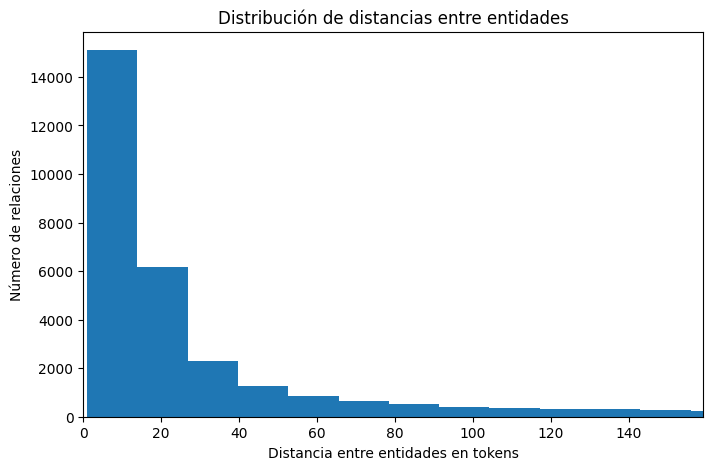

In [38]:
plt.figure(figsize=(8, 5))
plt.hist(df_dist["token_distance"], bins=50)
plt.xlabel("Distancia entre entidades en tokens")
plt.ylabel("Número de relaciones")
plt.title("Distribución de distancias entre entidades")
plt.xlim(0, df_dist["token_distance"].quantile(0.95))
plt.show()

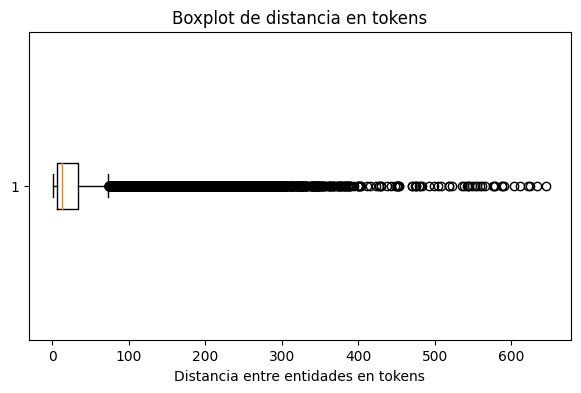

In [39]:
plt.figure(figsize=(7, 4))
plt.boxplot(df_dist["token_distance"], vert=False)
plt.xlabel("Distancia entre entidades en tokens")
plt.title("Boxplot de distancia en tokens")
plt.show()

<Figure size 1000x600 with 0 Axes>

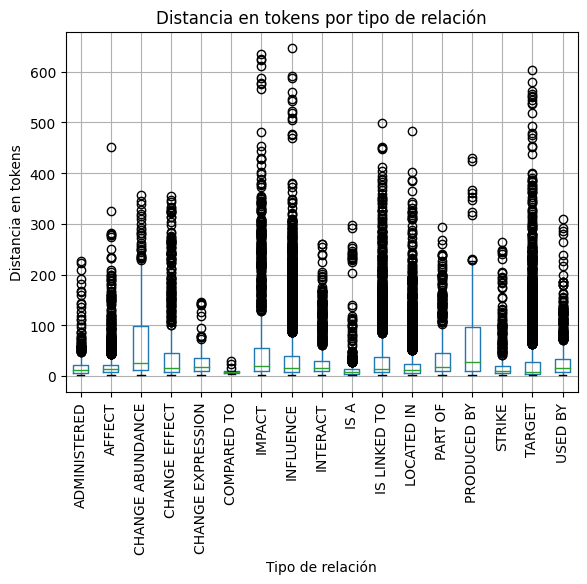

In [41]:
plt.figure(figsize=(10, 6))
df_dist.boxplot(column="token_distance", by="relation", rot=90)
plt.title("Distancia en tokens por tipo de relación")
plt.suptitle("")
plt.xlabel("Tipo de relación")
plt.ylabel("Distancia en tokens")
plt.show()

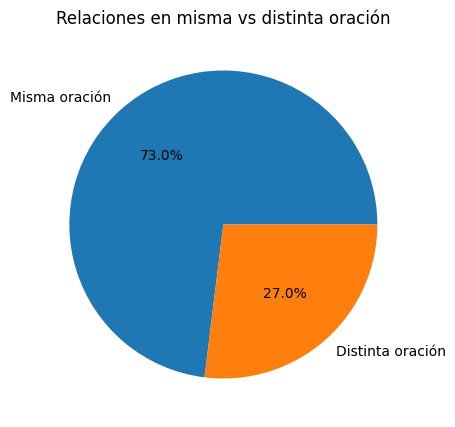

In [42]:
same_sent_counts = df_dist["same_sentence"].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(
    same_sent_counts,
    labels=["Misma oración" if x else "Distinta oración" for x in same_sent_counts.index],
    autopct="%1.1f%%"
)
plt.title("Relaciones en misma vs distinta oración")
plt.show()

## Análisis errores RE


In [33]:
import json

In [34]:
with open("../RE/relations.json", "r") as file:
    predictions = json.load(file)

In [35]:
from collections import defaultdict
import pandas as pd


def evaluate_re(
    ground_truth,
    predictions,
    legal_predicate_labels=None,
    relation_field="mention_level_relations"
):
    """
    Evaluación de extracción de relaciones.

    Se considera una relación correcta solo si coincide exactamente:
    subject_text_span, subject_label, predicate, object_text_span, object_label.

    La matriz de confusión se calcula para casos donde coincide todo excepto
    el predicate. Es decir, mismo sujeto y objeto, pero posible relación distinta.
    """

    ground_truth_RE = {}
    count_annotated_relations_per_predicate = {}

    # ---------- GOLD ----------
    for pmid, article in ground_truth.items():
        ground_truth_RE[pmid] = []

        try:
            relations = article[relation_field]
        except KeyError:
            raise KeyError(f'{pmid} - Not able to find field "{relation_field}" within article')

        for relation in relations:
            try:
                subject_text_span = str(relation["subject_text_span"])
                subject_label = str(relation["subject_label"])
                predicate = str(relation["predicate"])
                object_text_span = str(relation["object_text_span"])
                object_label = str(relation["object_label"])
            except KeyError:
                raise KeyError(
                    f"{pmid} - Missing expected fields for relation: {relation}"
                )

            entry = (
                subject_text_span,
                subject_label,
                predicate,
                object_text_span,
                object_label
            )

            ground_truth_RE[pmid].append(entry)

            count_annotated_relations_per_predicate[predicate] = (
                count_annotated_relations_per_predicate.get(predicate, 0) + 1
            )

    predicates = list(count_annotated_relations_per_predicate.keys())

    count_predicted_relations_per_predicate = {
        predicate: 0 for predicate in predicates
    }

    count_true_positives_per_predicate = {
        predicate: 0 for predicate in predicates
    }

    # Para matriz de confusión:
    # clave sin predicate -> predicate gold
    gold_by_subject_object = defaultdict(dict)

    for pmid, entries in ground_truth_RE.items():
        for (
            subject_text_span,
            subject_label,
            predicate,
            object_text_span,
            object_label
        ) in entries:

            key_without_predicate = (
                subject_text_span,
                subject_label,
                object_text_span,
                object_label
            )

            gold_by_subject_object[pmid][key_without_predicate] = predicate

    confusion_counts = defaultdict(lambda: defaultdict(int))

    # ---------- PREDICTIONS ----------
    for pmid in predictions.keys():
        try:
            relations = predictions[pmid][relation_field]
        except KeyError:
            raise KeyError(f'{pmid} - Not able to find field "{relation_field}" within article')

        # Eliminar duplicados exactos en predicciones
        seen_predictions = set()

        for relation in relations:
            try:
                subject_text_span = str(relation["subject_text_span"])
                subject_label = str(relation["subject_label"])
                predicate = str(relation["predicate"])
                object_text_span = str(relation["object_text_span"])
                object_label = str(relation["object_label"])
            except KeyError:
                raise KeyError(
                    f"{pmid} - Missing expected fields for relation: {relation}"
                )

            if legal_predicate_labels is not None and predicate not in legal_predicate_labels:
                raise NameError(
                    f"{pmid} - Illegal predicate {predicate} for relation: {relation}"
                )

            entry = (
                subject_text_span,
                subject_label,
                predicate,
                object_text_span,
                object_label
            )

            if entry in seen_predictions:
                continue

            seen_predictions.add(entry)

            # Si aparece una clase predicha que no estaba en gold,
            # la añadimos para poder contar sus FP
            if predicate not in count_predicted_relations_per_predicate:
                count_predicted_relations_per_predicate[predicate] = 0

            if predicate not in count_true_positives_per_predicate:
                count_true_positives_per_predicate[predicate] = 0

            count_predicted_relations_per_predicate[predicate] += 1

            # TP: match exacto de la relación completa
            if pmid in ground_truth_RE and entry in ground_truth_RE[pmid]:
                count_true_positives_per_predicate[predicate] += 1

            # Confusion matrix: mismo sujeto y objeto, pero predicate posiblemente distinto
            key_without_predicate = (
                subject_text_span,
                subject_label,
                object_text_span,
                object_label
            )

            if (
                pmid in gold_by_subject_object
                and key_without_predicate in gold_by_subject_object[pmid]
            ):
                gold_predicate = gold_by_subject_object[pmid][key_without_predicate]
                pred_predicate = predicate
                confusion_counts[gold_predicate][pred_predicate] += 1

    # ---------- MÉTRICAS POR CLASE ----------
    all_predicates = sorted(
        set(count_annotated_relations_per_predicate.keys())
        | set(count_predicted_relations_per_predicate.keys())
    )

    rows = []

    for predicate in all_predicates:
        tp = count_true_positives_per_predicate.get(predicate, 0)
        pred = count_predicted_relations_per_predicate.get(predicate, 0)
        gold = count_annotated_relations_per_predicate.get(predicate, 0)

        fp = pred - tp
        fn = gold - tp

        precision = tp / (pred + 1e-10)
        recall = tp / (gold + 1e-10)
        f1 = 2 * precision * recall / (precision + recall + 1e-10)

        rows.append({
            "predicate": predicate,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "gold_count": gold,
            "pred_count": pred,
            "TP/gold_count": tp / (gold + 1e-10),
            "precision": precision,
            "recall": recall,
            "f1": f1
        })

    per_class_df = pd.DataFrame(rows).sort_values("predicate")

    # ---------- MÉTRICAS GLOBALES ----------
    total_tp = sum(count_true_positives_per_predicate.values())
    total_pred = sum(count_predicted_relations_per_predicate.values())
    total_gold = sum(count_annotated_relations_per_predicate.values())

    micro_precision = total_tp / (total_pred + 1e-10)
    micro_recall = total_tp / (total_gold + 1e-10)
    micro_f1 = 2 * micro_precision * micro_recall / (
        micro_precision + micro_recall + 1e-10
    )

    macro_precision = per_class_df["precision"].mean()
    macro_recall = per_class_df["recall"].mean()
    macro_f1 = per_class_df["f1"].mean()

    global_metrics = {
        "precision_macro": macro_precision,
        "recall_macro": macro_recall,
        "f1_macro": macro_f1,
        "precision_micro": micro_precision,
        "recall_micro": micro_recall,
        "f1_micro": micro_f1,
        "TP": total_tp,
        "FP": total_pred - total_tp,
        "FN": total_gold - total_tp,
        "gold_total": total_gold,
        "pred_total": total_pred,
    }

    # ---------- MATRIZ DE CONFUSIÓN ----------
    confusion_labels = sorted(
        set(all_predicates)
        | {
            pred_predicate
            for gold_predicate in confusion_counts
            for pred_predicate in confusion_counts[gold_predicate]
        }
    )

    confusion_df = pd.DataFrame(
        0,
        index=confusion_labels,
        columns=confusion_labels
    )

    for gold_predicate, pred_dict in confusion_counts.items():
        for pred_predicate, count in pred_dict.items():
            confusion_df.loc[gold_predicate, pred_predicate] = count

    return global_metrics, per_class_df, confusion_df

In [36]:
metrics, per_class, confusion = evaluate_re(golden, predictions)

In [37]:
print(metrics)
print(per_class)

{'precision_macro': 0.5606209016724504, 'recall_macro': 0.36827385188493167, 'f1_macro': 0.42533708811713644, 'precision_micro': 0.631313131312972, 'recall_micro': 0.4340277777777024, 'f1_micro': 0.5144032921326789, 'TP': 250, 'FP': 146, 'FN': 326, 'gold_total': 576, 'pred_total': 396}
            predicate  TP  FP  FN  gold_count  pred_count  TP/gold_count  \
0        administered   5   9  20          25          14       0.200000   
1              affect  14  16  40          54          30       0.259259   
2    change abundance   1   6   5           6           7       0.166667   
3       change effect   9   2   3          12          11       0.750000   
4   change expression   0   0   5           5           0       0.000000   
5         compared to   1   0   2           3           1       0.333333   
6              impact  13   7  17          30          20       0.433333   
7           influence  50  27  48          98          77       0.510204   
8            interact   5  13

In [38]:
from collections import defaultdict
import pandas as pd


def evaluate_re(
    ground_truth,
    predictions,
    legal_predicate_labels=None,
    relation_field="mention_level_relations",
    min_gold_count=10
):
    """
    Evaluación de extracción de relaciones.

    Se considera una relación correcta solo si coincide exactamente:
    subject_text_span, subject_label, predicate, object_text_span, object_label.

    Solo se calculan métricas para predicados con gold_count >= min_gold_count.

    La matriz de confusión se calcula para casos donde coincide todo excepto
    el predicate. Es decir, mismo sujeto y objeto, pero posible relación distinta.
    """

    ground_truth_RE = {}
    count_annotated_relations_per_predicate = {}

    # ---------- GOLD ----------
    for pmid, article in ground_truth.items():
        ground_truth_RE[pmid] = []

        try:
            relations = article[relation_field]
        except KeyError:
            raise KeyError(f'{pmid} - Not able to find field "{relation_field}" within article')

        for relation in relations:
            try:
                subject_text_span = str(relation["subject_text_span"])
                subject_label = str(relation["subject_label"])
                predicate = str(relation["predicate"])
                object_text_span = str(relation["object_text_span"])
                object_label = str(relation["object_label"])
            except KeyError:
                raise KeyError(
                    f"{pmid} - Missing expected fields for relation: {relation}"
                )

            entry = (
                subject_text_span,
                subject_label,
                predicate,
                object_text_span,
                object_label
            )

            ground_truth_RE[pmid].append(entry)

            count_annotated_relations_per_predicate[predicate] = (
                count_annotated_relations_per_predicate.get(predicate, 0) + 1
            )

    # Predicados que sí entran en la evaluación
    included_predicates = {
        predicate
        for predicate, count in count_annotated_relations_per_predicate.items()
        if count >= min_gold_count
    }

    # Predicados excluidos por baja frecuencia
    excluded_predicates = {
        predicate
        for predicate, count in count_annotated_relations_per_predicate.items()
        if count < min_gold_count
    }

    count_predicted_relations_per_predicate = {
        predicate: 0 for predicate in included_predicates
    }

    count_true_positives_per_predicate = {
        predicate: 0 for predicate in included_predicates
    }

    # Para matriz de confusión:
    # clave sin predicate -> lista de predicates gold
    # Uso lista por si un mismo par sujeto-objeto tiene varias relaciones gold.
    gold_by_subject_object = defaultdict(lambda: defaultdict(list))

    for pmid, entries in ground_truth_RE.items():
        for (
            subject_text_span,
            subject_label,
            predicate,
            object_text_span,
            object_label
        ) in entries:

            # Ignoramos relaciones gold excluidas
            if predicate not in included_predicates:
                continue

            key_without_predicate = (
                subject_text_span,
                subject_label,
                object_text_span,
                object_label
            )

            gold_by_subject_object[pmid][key_without_predicate].append(predicate)

    confusion_counts = defaultdict(lambda: defaultdict(int))

    # ---------- PREDICTIONS ----------
    for pmid in predictions.keys():
        try:
            relations = predictions[pmid][relation_field]
        except KeyError:
            raise KeyError(f'{pmid} - Not able to find field "{relation_field}" within article')

        # Eliminar duplicados exactos en predicciones
        seen_predictions = set()

        for relation in relations:
            try:
                subject_text_span = str(relation["subject_text_span"])
                subject_label = str(relation["subject_label"])
                predicate = str(relation["predicate"])
                object_text_span = str(relation["object_text_span"])
                object_label = str(relation["object_label"])
            except KeyError:
                raise KeyError(
                    f"{pmid} - Missing expected fields for relation: {relation}"
                )

            if legal_predicate_labels is not None and predicate not in legal_predicate_labels:
                raise NameError(
                    f"{pmid} - Illegal predicate {predicate} for relation: {relation}"
                )

            # Ignoramos predicciones de clases excluidas por baja frecuencia
            if predicate not in included_predicates:
                continue

            entry = (
                subject_text_span,
                subject_label,
                predicate,
                object_text_span,
                object_label
            )

            if entry in seen_predictions:
                continue

            seen_predictions.add(entry)

            count_predicted_relations_per_predicate[predicate] += 1

            # TP: match exacto de la relación completa
            if pmid in ground_truth_RE and entry in ground_truth_RE[pmid]:
                count_true_positives_per_predicate[predicate] += 1

            # Confusion matrix: mismo sujeto y objeto, pero predicate posiblemente distinto
            key_without_predicate = (
                subject_text_span,
                subject_label,
                object_text_span,
                object_label
            )

            if (
                pmid in gold_by_subject_object
                and key_without_predicate in gold_by_subject_object[pmid]
            ):
                gold_predicates = gold_by_subject_object[pmid][key_without_predicate]
                pred_predicate = predicate

                for gold_predicate in gold_predicates:
                    # Solo incluimos confusiones entre clases incluidas
                    if gold_predicate in included_predicates and pred_predicate in included_predicates:
                        confusion_counts[gold_predicate][pred_predicate] += 1

    # ---------- MÉTRICAS POR CLASE ----------
    rows = []

    for predicate in sorted(included_predicates):
        tp = count_true_positives_per_predicate.get(predicate, 0)
        pred = count_predicted_relations_per_predicate.get(predicate, 0)
        gold = count_annotated_relations_per_predicate.get(predicate, 0)

        fp = pred - tp
        fn = gold - tp

        precision = tp / (pred + 1e-10)
        recall = tp / (gold + 1e-10)
        f1 = 2 * precision * recall / (precision + recall + 1e-10)

        rows.append({
            "predicate": predicate,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "gold_count": gold,
            "pred_count": pred,
            "TP/gold_count": tp / (gold + 1e-10),
            "precision": precision,
            "recall": recall,
            "f1": f1
        })

    per_class_df = pd.DataFrame(rows).sort_values("predicate")

    # ---------- MÉTRICAS GLOBALES ----------
    total_tp = sum(count_true_positives_per_predicate.values())
    total_pred = sum(count_predicted_relations_per_predicate.values())
    total_gold = sum(
        count_annotated_relations_per_predicate[predicate]
        for predicate in included_predicates
    )

    micro_precision = total_tp / (total_pred + 1e-10)
    micro_recall = total_tp / (total_gold + 1e-10)
    micro_f1 = 2 * micro_precision * micro_recall / (
        micro_precision + micro_recall + 1e-10
    )

    macro_precision = per_class_df["precision"].mean()
    macro_recall = per_class_df["recall"].mean()
    macro_f1 = per_class_df["f1"].mean()

    global_metrics = {
        "min_gold_count": min_gold_count,
        "included_predicates": sorted(included_predicates),
        "excluded_predicates": sorted(excluded_predicates),

        "precision_macro": macro_precision,
        "recall_macro": macro_recall,
        "f1_macro": macro_f1,
        "precision_micro": micro_precision,
        "recall_micro": micro_recall,
        "f1_micro": micro_f1,

        "TP": total_tp,
        "FP": total_pred - total_tp,
        "FN": total_gold - total_tp,
        "gold_total": total_gold,
        "pred_total": total_pred,
    }

    # ---------- MATRIZ DE CONFUSIÓN ----------
    confusion_labels = sorted(included_predicates)

    confusion_df = pd.DataFrame(
        0,
        index=confusion_labels,
        columns=confusion_labels
    )

    for gold_predicate, pred_dict in confusion_counts.items():
        for pred_predicate, count in pred_dict.items():
            if gold_predicate in included_predicates and pred_predicate in included_predicates:
                confusion_df.loc[gold_predicate, pred_predicate] = count

    return global_metrics, per_class_df, confusion_df

In [40]:
global_metrics, per_class_df, confusion_df = evaluate_re(
    golden,
    predictions,
    relation_field="mention_level_relations",
    min_gold_count=10
)

In [41]:
print(global_metrics)
print(per_class_df)

{'min_gold_count': 10, 'included_predicates': ['administered', 'affect', 'change effect', 'impact', 'influence', 'interact', 'is a', 'is linked to', 'located in', 'part of', 'strike', 'target', 'used by'], 'excluded_predicates': ['change abundance', 'change expression', 'compared to', 'produced by'], 'precision_macro': 0.5682844758289658, 'recall_macro': 0.4277427293893637, 'f1_macro': 0.480273154689638, 'precision_micro': 0.6382428940566827, 'recall_micro': 0.4434470377018952, 'f1_micro': 0.5233050846972734, 'TP': 247, 'FP': 140, 'FN': 310, 'gold_total': 557, 'pred_total': 387}
        predicate  TP  FP  FN  gold_count  pred_count  TP/gold_count  \
0    administered   5   9  20          25          14       0.200000   
1          affect  14  16  40          54          30       0.259259   
2   change effect   9   2   3          12          11       0.750000   
3          impact  13   7  17          30          20       0.433333   
4       influence  50  27  48          98          77 

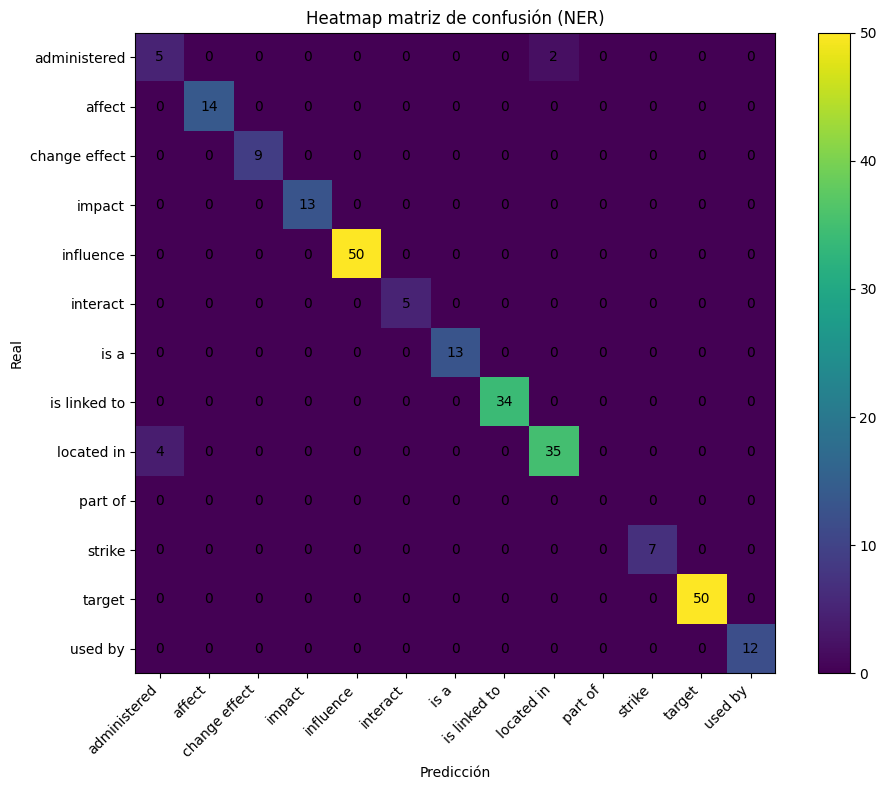

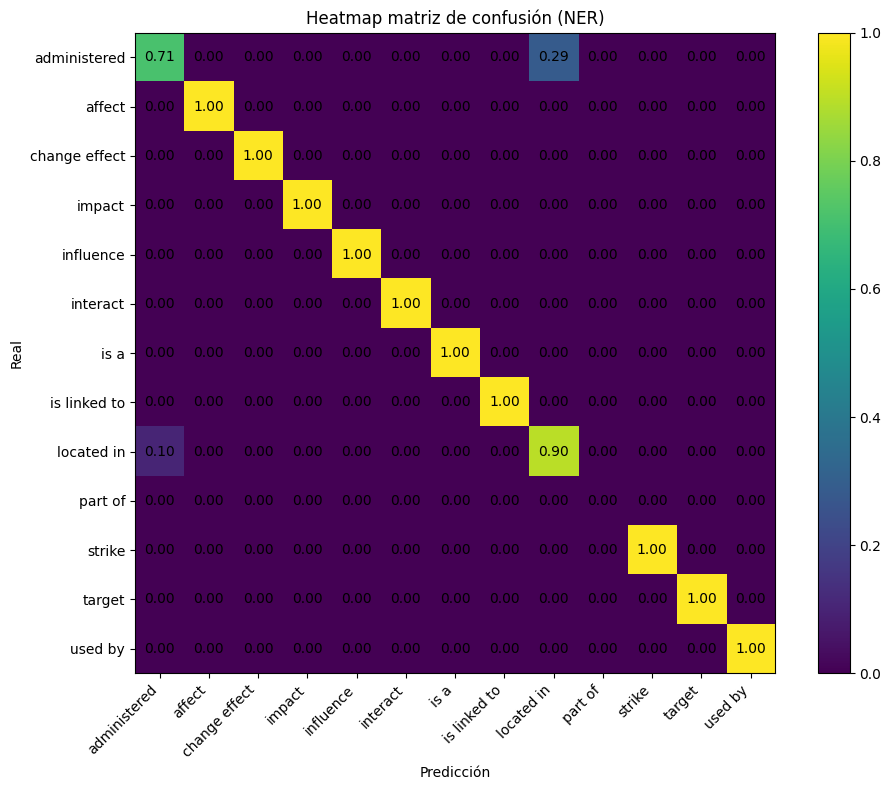

In [42]:
plot_confusion_heatmap(confusion_df)

# Heatmap normalizado (MUY recomendado)
plot_confusion_heatmap(confusion_df, normalize=True)